# Advanced Ensemble Modeling and Final Evaluation

This notebook predicts **concrete compressive strength** using ensemble regression methods.

The structure intentionally follows the Ironhack ensemble-methods lesson:

1. Load the prepared data  
2. Separate features and target  
3. Perform the train/test split  
4. Normalize the feature data  
5. Fit each ensemble model  
6. Generate predictions with `.predict(X_test_norm)`  
7. Calculate MAE, RMSE, and R²  
8. Compare the models  
9. Tune the strongest model  
10. Examine residuals and feature importance

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import (
    AdaBoostRegressor,
    BaggingRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
TEST_SIZE = 0.20

In [5]:
data_path = Path(
    "../Processed_Data/concrete_engineered.csv"
)

concrete = pd.read_csv(data_path)

concrete.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength,binder_total,aggregate_total,water_binder_ratio,aggregate_binder_ratio
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,540.0,1716.0,0.30000,3.177778
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,540.0,1731.0,0.30000,3.205556
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,475.0,1526.0,0.48000,3.212632
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,475.0,1526.0,0.48000,3.212632
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,331.0,1803.9,0.58006,5.449849


In [6]:
required_engineered_features = {
    "binder_total",
    "aggregate_total",
    "water_binder_ratio",
    "aggregate_binder_ratio"
}

if not required_engineered_features.issubset(concrete.columns):
    concrete = concrete.copy()

    concrete["binder_total"] = (
        concrete["cement"]
        + concrete["blast_furnace_slag"]
        + concrete["fly_ash"]
    )

    concrete["aggregate_total"] = (
        concrete["coarse_aggregate"]
        + concrete["fine_aggregate"]
    )

    concrete["water_binder_ratio"] = (
        concrete["water"] / concrete["binder_total"]
    )

    concrete["aggregate_binder_ratio"] = (
        concrete["aggregate_total"] / concrete["binder_total"]
    )

print("Columns used in this notebook:")
print(concrete.columns.tolist())

Columns used in this notebook:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength', 'binder_total', 'aggregate_total', 'water_binder_ratio', 'aggregate_binder_ratio']


In [7]:
target_column = "concrete_compressive_strength"

X = concrete.drop(columns=target_column)
y = concrete[target_column]

print(f"Number of predictors: {X.shape[1]}")
print(f"Target: {target_column}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Number of predictors: 12
Target: concrete_compressive_strength
X shape: (1005, 12)
y shape: (1005,)


## 4. Perform the train/test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Training rows: 804
Test rows: 201


## 5. Normalize the feature data

The scaler is fitted on the training features only. The fitted scaler is then used to transform both the training and test features.

The target is not normalized because the final predictions should remain interpretable in **MPa**.

In [9]:
normalizer = MinMaxScaler()

normalizer.fit(X_train)

X_train_norm = normalizer.transform(X_train)
X_test_norm = normalizer.transform(X_test)

In [10]:
X_train_norm = pd.DataFrame(
    X_train_norm,
    columns=X_train.columns,
    index=X_train.index
)

X_test_norm = pd.DataFrame(
    X_test_norm,
    columns=X_test.columns,
    index=X_test.index
)

X_train_norm.head()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,binder_total,aggregate_total,water_binder_ratio,aggregate_binder_ratio
78,0.980137,0.00000,0.000000,0.159872,0.875776,0.153315,0.751882,0.005495,0.752955,0.562963,0.047854,0.121676
29,0.851598,0.00000,0.000000,0.848921,0.000000,0.393039,0.000000,0.016484,0.625000,0.134503,0.368351,0.111872
280,0.399772,0.00000,0.486757,0.310152,0.366460,0.518752,0.706473,0.005495,0.396591,0.765107,0.291408,0.342817
507,0.762557,0.00000,0.000000,0.768985,0.000000,0.112211,0.315354,0.074176,0.536364,0.197076,0.398430,0.160175
652,0.147945,0.69616,0.000000,0.653078,0.000000,0.523852,0.247366,0.016484,0.493182,0.411696,0.380397,0.217292


## 6. Create a consistent evaluation function

Every model follows the class workflow:

```python
model.fit(X_train_norm, y_train)
predictions = model.predict(X_test_norm)
```

The prediction arrays are then evaluated with MAE, RMSE, and R².

In [11]:
def evaluate_predictions(model_name, y_true, y_pred):
    """Return the main regression metrics for one model."""

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"{model_name}")
    print(f"MAE: {mae:.2f} MPa")
    print(f"RMSE: {rmse:.2f} MPa")
    print(f"R²: {r2:.3f}")

    return {
        "model": model_name,
        "test_mae": mae,
        "test_rmse": rmse,
        "test_r2": r2
    }


model_results = []

In [13]:
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=20,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    max_samples=0.80,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_model.fit(X_train_norm, y_train)

y_pred_bagging = bagging_model.predict(X_test_norm)

bagging_results = evaluate_predictions(
    "Bagging",
    y_test,
    y_pred_bagging
)

model_results.append(bagging_results)

Bagging
MAE: 3.72 MPa
RMSE: 5.17 MPa
R²: 0.910


## 8. Pasting
Pasting is similar to bagging, but the training rows are sampled **without replacement** because `bootstrap=False`.

In [14]:
pasting_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=20,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    max_samples=0.80,
    bootstrap=False,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

pasting_model.fit(X_train_norm, y_train)

y_pred_pasting = pasting_model.predict(X_test_norm)

pasting_results = evaluate_predictions(
    "Pasting",
    y_test,
    y_pred_pasting
)

model_results.append(pasting_results)

Pasting
MAE: 3.23 MPa
RMSE: 4.75 MPa
R²: 0.924


## 9. Random Patches
Random Patches introduces randomness in both:

- the training rows used by each estimator; and
- the features used by each estimator.

This is implemented here with `BaggingRegressor` by setting both row-sampling and feature-sampling parameters.

In [15]:
random_patches_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=20,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    max_samples=0.80,
    max_features=0.80,
    bootstrap=True,
    bootstrap_features=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_patches_model.fit(X_train_norm, y_train)

y_pred_random_patches = random_patches_model.predict(X_test_norm)

random_patches_results = evaluate_predictions(
    "Random Patches",
    y_test,
    y_pred_random_patches
)

model_results.append(random_patches_results)

Random Patches
MAE: 5.79 MPa
RMSE: 7.35 MPa
R²: 0.819


## 10. Random Forest
A Random Forest trains many decision trees on bootstrapped row samples and considers a random subset of features at each split.

In [16]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_model.fit(X_train_norm, y_train)

y_pred_random_forest = random_forest_model.predict(X_test_norm)

random_forest_results = evaluate_predictions(
    "Random Forest",
    y_test,
    y_pred_random_forest
)

model_results.append(random_forest_results)

Random Forest
MAE: 3.57 MPa
RMSE: 5.04 MPa
R²: 0.915


## 11. AdaBoost
AdaBoost builds estimators sequentially. Later estimators place greater emphasis on observations that earlier estimators predicted poorly.

In [17]:
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=3,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    learning_rate=0.10,
    random_state=RANDOM_STATE
)

ada_model.fit(X_train_norm, y_train)

y_pred_ada = ada_model.predict(X_test_norm)

ada_results = evaluate_predictions(
    "AdaBoost",
    y_test,
    y_pred_ada
)

model_results.append(ada_results)

AdaBoost
MAE: 6.16 MPa
RMSE: 8.04 MPa
R²: 0.783


## 12. Gradient Boosting
Gradient Boosting also builds trees sequentially. Each new tree is trained to reduce the errors left by the current ensemble.

In [18]:
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.10,
    max_depth=3,
    random_state=RANDOM_STATE
)

gradient_boosting_model.fit(X_train_norm, y_train)

y_pred_gradient_boosting = gradient_boosting_model.predict(X_test_norm)

gradient_boosting_results = evaluate_predictions(
    "Gradient Boosting",
    y_test,
    y_pred_gradient_boosting
)

model_results.append(gradient_boosting_results)

Gradient Boosting
MAE: 3.81 MPa
RMSE: 5.35 MPa
R²: 0.904


In [19]:
ensemble_results = (
    pd.DataFrame(model_results)
    .sort_values("test_mae")
    .reset_index(drop=True)
)

ensemble_results

,model,test_mae,test_rmse,test_r2
0,Pasting,3.228435,4.747880,0.924437
1,Random Forest,3.569419,5.041814,0.914791
2,Bagging,3.723064,5.170272,0.910394
3,Bagging,3.723064,5.170272,0.910394
4,Gradient Boosting,3.806957,5.351257,0.904011
5,Random Patches,5.786348,7.348388,0.818993
6,AdaBoost,6.164603,8.038674,0.783390


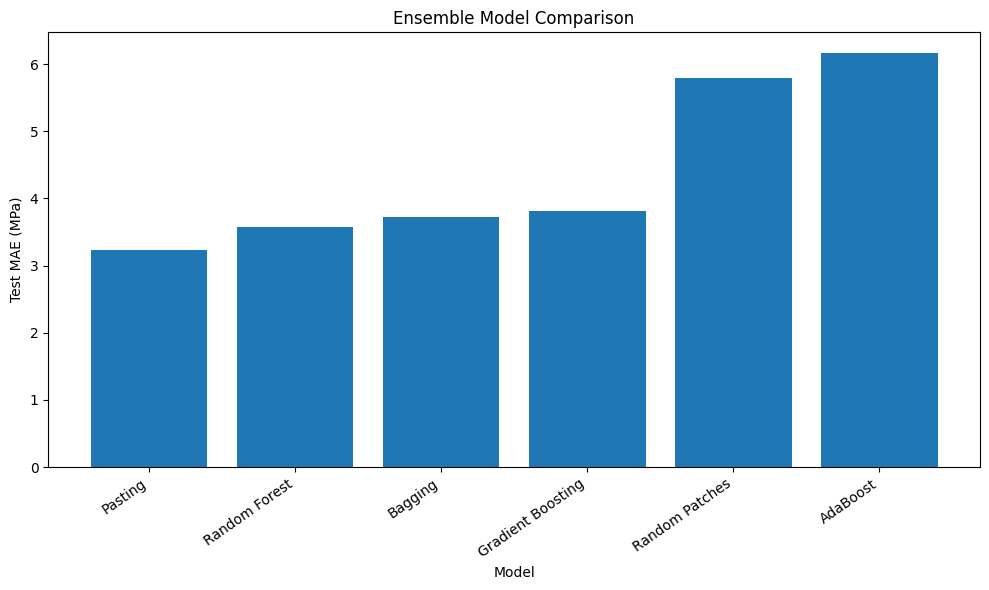

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    ensemble_results["model"],
    ensemble_results["test_mae"]
)

plt.title("Ensemble Model Comparison")
plt.xlabel("Model")
plt.ylabel("Test MAE (MPa)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Initial ensemble interpretation

The strongest model should have:

- the lowest MAE;
- the lowest RMSE; and
- the highest R².

The three metrics should be interpreted together rather than selecting a model from only one number.

## 14. Tune Gradient Boosting

The class notebook ends by noting that the models have not been fine-tuned. This project continues that workflow by tuning Gradient Boosting with `GridSearchCV`.

The grid search is fitted only on the normalized training data. It uses five-fold cross-validation and selects the parameter combination with the lowest cross-validated MAE.

In [22]:
pasting_parameter_grid = {
    "n_estimators": [100, 200, 300],
    "max_samples": [0.70, 0.85, 1.00],
    "estimator__max_depth": [None, 10, 20],
    "estimator__min_samples_leaf": [1, 2, 4]
}

pasting_grid_search = GridSearchCV(
    estimator=BaggingRegressor(
        estimator=DecisionTreeRegressor(
            random_state=RANDOM_STATE
        ),
        bootstrap=False,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_grid=pasting_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    refit=True
)

pasting_grid_search.fit(
    X_train_norm,
    y_train
)

print("Best Pasting parameters:")
print(pasting_grid_search.best_params_)

print(
    "Best Pasting cross-validated MAE:",
    -pasting_grid_search.best_score_
)

Best Pasting parameters:
{'estimator__max_depth': None, 'estimator__min_samples_leaf': 1, 'max_samples': 0.85, 'n_estimators': 200}
Best Pasting cross-validated MAE: 3.5366501504270182


In [21]:
gradient_boosting_parameter_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.05, 0.10],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [1, 2, 4]
}

gradient_boosting_grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    param_grid=gradient_boosting_parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1,
    refit=True
)

gradient_boosting_grid_search.fit(
    X_train_norm,
    y_train
)

print("Best parameters:")
print(gradient_boosting_grid_search.best_params_)

print(
    "Best cross-validated MAE:",
    -gradient_boosting_grid_search.best_score_
)

Best parameters:
{'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 300}
Best cross-validated MAE: 2.868933107215856


In [23]:
tuned_gradient_boosting_model = (
    gradient_boosting_grid_search.best_estimator_
)

y_pred_tuned_gradient_boosting = (
    tuned_gradient_boosting_model.predict(X_test_norm)
)

tuned_gradient_boosting_results = evaluate_predictions(
    "Tuned Gradient Boosting",
    y_test,
    y_pred_tuned_gradient_boosting
)

Tuned Gradient Boosting
MAE: 2.66 MPa
RMSE: 4.21 MPa
R²: 0.941


In [24]:
final_model_results = pd.concat(
    [
        ensemble_results,
        pd.DataFrame([tuned_gradient_boosting_results])
    ],
    ignore_index=True
)

final_model_results = (
    final_model_results
    .sort_values("test_mae")
    .reset_index(drop=True)
)

final_model_results

,model,test_mae,test_rmse,test_r2
0,Tuned Gradient Boosting,2.656309,4.210837,0.940564
1,Pasting,3.228435,4.747880,0.924437
2,Random Forest,3.569419,5.041814,0.914791
3,Bagging,3.723064,5.170272,0.910394
4,Bagging,3.723064,5.170272,0.910394
5,Gradient Boosting,3.806957,5.351257,0.904011
6,Random Patches,5.786348,7.348388,0.818993
7,AdaBoost,6.164603,8.038674,0.783390


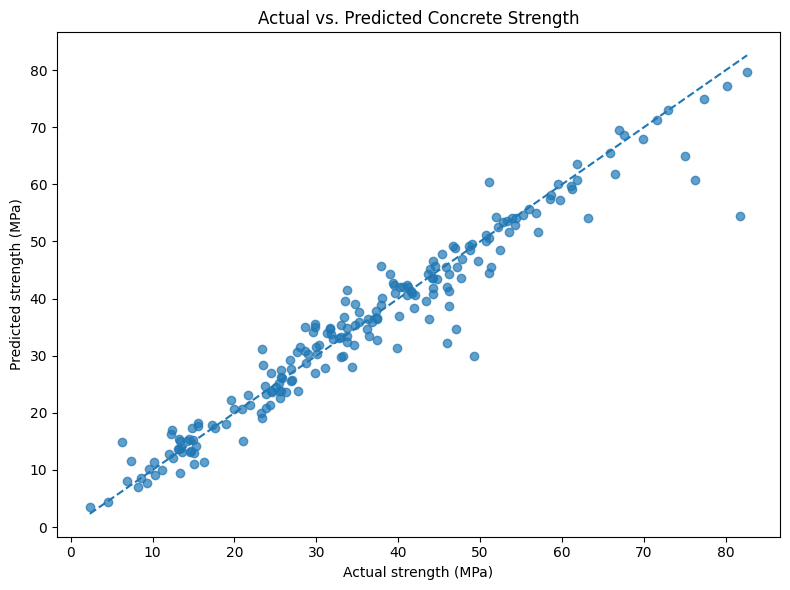

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_tuned_gradient_boosting,
    alpha=0.70
)

minimum_value = min(
    y_test.min(),
    y_pred_tuned_gradient_boosting.min()
)

maximum_value = max(
    y_test.max(),
    y_pred_tuned_gradient_boosting.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.title("Actual vs. Predicted Concrete Strength")
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.tight_layout()
plt.show()

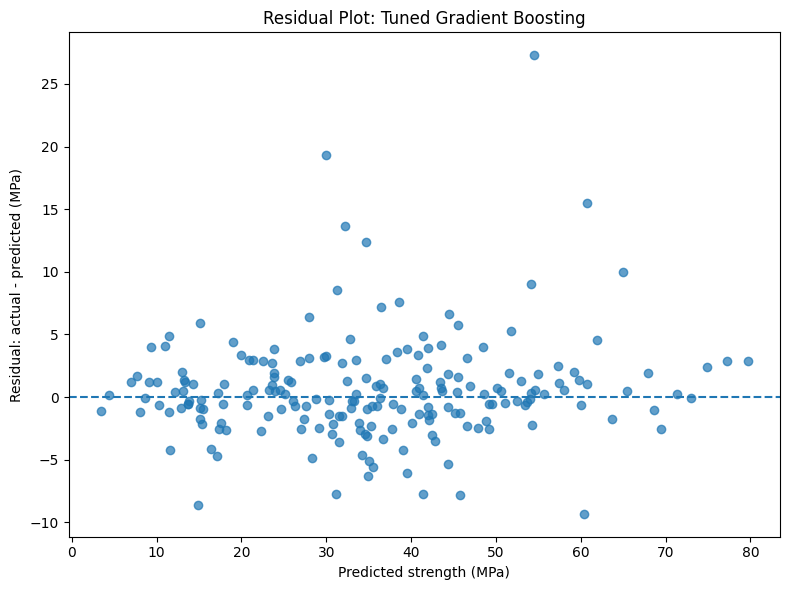

In [26]:
residuals = (
    y_test.to_numpy()
    - y_pred_tuned_gradient_boosting
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_tuned_gradient_boosting,
    residuals,
    alpha=0.70
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot: Tuned Gradient Boosting")
plt.xlabel("Predicted strength (MPa)")
plt.ylabel("Residual: actual - predicted (MPa)")
plt.tight_layout()
plt.show()

In [27]:
feature_importance = (
    pd.DataFrame({
        "feature": X_train_norm.columns,
        "importance": tuned_gradient_boosting_model.feature_importances_
    })
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance

,feature,importance
0,age,0.383608
1,water_binder_ratio,0.345334
2,cement,0.090418
3,binder_total,0.080461
4,fly_ash,0.018492
5,water,0.014744
6,superplasticizer,0.013928
7,fine_aggregate,0.013080
8,blast_furnace_slag,0.012525
9,coarse_aggregate,0.009613


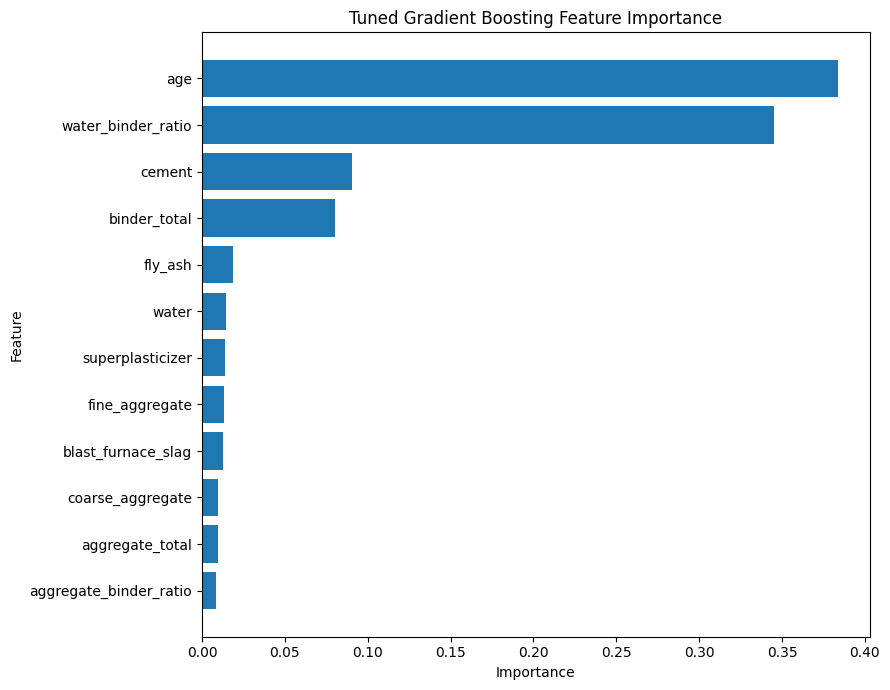

In [28]:
plt.figure(figsize=(9, 7))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.gca().invert_yaxis()
plt.title("Tuned Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [29]:
models_directory = Path("Models")
models_directory.mkdir(exist_ok=True)

joblib.dump(
    tuned_gradient_boosting_model,
    models_directory / "tuned_gradient_boosting_model.joblib"
)

joblib.dump(
    normalizer,
    models_directory / "minmax_scaler.joblib"
)

joblib.dump(
    X_train_norm.columns.tolist(),
    models_directory / "model_feature_order.joblib"
)

print("Model, scaler, and feature order saved.")

Model, scaler, and feature order saved.
